# EP3 Machine Learning — Caso C: Predicción de popularidad de canciones (Spotify)
**MLY1101** · Nicolás Garrido · Karen Manríquez · Felipe Espinoza

## Introducción

Un sello discográfico (o un equipo de curadores de playlists) recibe miles de canciones nuevas y no puede promocionarlas todas. Necesita una forma de **estimar qué tan popular puede llegar a ser una canción** a partir de sus características, para decidir dónde poner el presupuesto de marketing y qué temas proponer a las playlists.

- **Problema de ML:** regresión. Queremos predecir `popularity`, un número de 0 a 100 que calcula Spotify.
- **Objetivo general:** construir un modelo que estime la popularidad de una canción a partir de sus características musicales y su género.
- **Objetivos específicos:**
  1. Explorar los datos y encontrar qué variables se relacionan con la popularidad.
  2. Entrenar y comparar varios modelos, **optimizando sus hiperparámetros** con validación cruzada.
  3. Probar **técnicas de ensamble** (bagging, boosting y voting) y medir si mejoran el resultado.
  4. Evaluar si el modelo **generaliza** a canciones nuevas.
  5. Agrupar las canciones con **K-Means** para encontrar perfiles musicales.

**KPIs:**

| KPI | Meta |
|---|---|
| R² en test | ≥ 0,40 |
| MAE (error promedio en puntos de popularidad) | ≤ 11 puntos |
| Mejora del RMSE frente al modelo base (predecir siempre el promedio) | ≥ 20 % |
| Diferencia entre validación cruzada y test (generalización) | ≤ 0,02 de R² |
| % de "hits" (popularidad ≥ 50) dentro del 10 % de canciones con mayor predicción | ≥ 60 % |

**Regla para elegir el modelo (definida antes de modelar):** gana el mayor R² en validación cruzada; si otros quedan a menos de 0,005, se elige el más simple. El test solo se usa para confirmar, nunca para elegir.

**Metodología:** CRISP-DM → comprensión del negocio, comprensión de los datos (EDA), preparación, modelado, evaluación y despliegue (guardar el modelo).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import time
import os
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, KFold, cross_val_score, cross_val_predict,
                                     GridSearchCV, RandomizedSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, silhouette_score

RANDOM_STATE = 42

# Carpetas para guardar gráficos y modelos (se crean si no existen, por ejemplo en Colab)
os.makedirs("../images", exist_ok=True)
os.makedirs("../models", exist_ok=True)
sns.set_theme(style="whitegrid")

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

## 1. Comprensión de los datos (EDA)
### 1.1 Carga

In [2]:
# Buscamos el CSV en las ubicaciones más comunes (carpeta del proyecto, carpeta actual o Colab)
import glob
candidatos = ["../data/Spotify_Tracks_Dataset.csv", "data/Spotify_Tracks_Dataset.csv", "Spotify_Tracks_Dataset.csv",
              "/content/Spotify_Tracks_Dataset.csv"] + glob.glob("/content/**/Spotify_Tracks_Dataset*.csv", recursive=True)
RUTA_DATOS = next((r for r in candidatos if os.path.exists(r)), None)
if RUTA_DATOS is None:
    raise FileNotFoundError("No se encontró Spotify_Tracks_Dataset.csv. Súbelo a la misma carpeta del notebook o a ../data/")
print("Leyendo:", RUTA_DATOS)
df_raw = pd.read_csv(RUTA_DATOS)
print(df_raw.shape)
df_raw.head()

Leyendo: ../data/Spotify_Tracks_Dataset.csv
(114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Soundtrack),Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


**Diccionario de variables** (dataset *Spotify Tracks*, Kaggle, obtenido de la API de Spotify). Cada fila es una canción asociada a un género.

| Tipo | Variables |
|---|---|
| Identificación | `track_id`, `artists`, `album_name`, `track_name` |
| **Objetivo** | `popularity` (0–100, la calcula Spotify según reproducciones recientes) |
| Características musicales (0 a 1) | `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` |
| Otras numéricas | `duration_ms`, `loudness` (dB), `tempo` (BPM) |
| Categóricas | `track_genre` (114 géneros), `key` (tono 0–11), `mode` (mayor/menor), `time_signature`, `explicit` |

### 1.2 Calidad de los datos

In [3]:
print("Nulos por columna:")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
print("\nFilas duplicadas:", df_raw.duplicated().sum())
print("track_id repetidos:", df_raw["track_id"].duplicated().sum())
print("Canciones repetidas (mismo artista y nombre):", df_raw.duplicated(["artists", "track_name"]).sum())
print("Canciones con popularidad 0:", (df_raw["popularity"] == 0).sum())

Nulos por columna:
artists       1
album_name    1
track_name    1
dtype: int64

Filas duplicadas: 0
track_id repetidos: 24259
Canciones repetidas (mismo artista y nombre): 32656
Canciones con popularidad 0: 16020


In [4]:
# Ejemplo: una misma canción aparece en varios géneros y en varias versiones (single, álbum, recopilatorio)
ejemplo = df_raw[df_raw.duplicated(["artists", "track_name"], keep=False)].sort_values(["artists", "track_name"])
ejemplo[["artists", "track_name", "album_name", "track_genre", "popularity"]].head(8)

,artists,track_name,album_name,track_genre,popularity
58516,(Hed) P.E.,Crazy Legs,Broke,industrial,25
58857,(Hed) P.E.,Crazy Legs,Broke,industrial,22
58306,(Hed) P.E.,Waiting to Die,Broke,industrial,27
58874,(Hed) P.E.,Waiting to Die,Broke,industrial,22
63488,10-FEET,SHOES,VANDALIZE,j-rock,34
100702,10-FEET,SHOES,VANDALIZE,ska,34
8319,10cc,Art For Art's Sake,Fiesta temática 70s,blues,0
34690,10cc,Art For Art's Sake,Fiesta temática 70s,folk,0


**Problemas encontrados:**
- `Unnamed: 0` es solo un índice → se elimina.
- **1 fila** con nulos en artista, álbum y nombre → se elimina.
- **24.259 `track_id` repetidos**: la misma canción aparece en varios géneros (por ejemplo, en "pop" y en "dance").
- Además, una misma canción aparece en **varias versiones** (single, álbum, recopilatorio) con distinta popularidad. Normalmente la versión principal es la popular y las otras tienen popularidad cercana a 0.

Si no limpiamos los duplicados, **la misma canción podría quedar en train y en test** y el modelo "haría trampa" (fuga de datos). Por eso nos quedamos con **una sola fila por canción**: la **primera** que aparece en el archivo.

Ojo: no elegimos "la versión más popular", porque eso sería usar la variable que queremos predecir para armar los datos, y subiría la popularidad promedio a propósito.

In [5]:
df = df_raw.drop(columns=["Unnamed: 0"]).dropna()
df = df.drop_duplicates("track_id", keep="first")
df = df.drop_duplicates(["artists", "track_name"], keep="first")
df = df.reset_index(drop=True)
print("Filas originales:", len(df_raw), " -> después de limpiar:", len(df))
print("Canciones con popularidad 0:", (df["popularity"] == 0).sum(), f"({(df['popularity'] == 0).mean():.1%})")

Filas originales: 114000  -> después de limpiar: 81343
Canciones con popularidad 0: 5451 (6.7%)


### 1.3 Variable objetivo: popularidad

count    81343.0
mean        34.6
std         19.4
min          0.0
25%         21.0
50%         35.0
75%         49.0
max        100.0
Name: popularity, dtype: float64


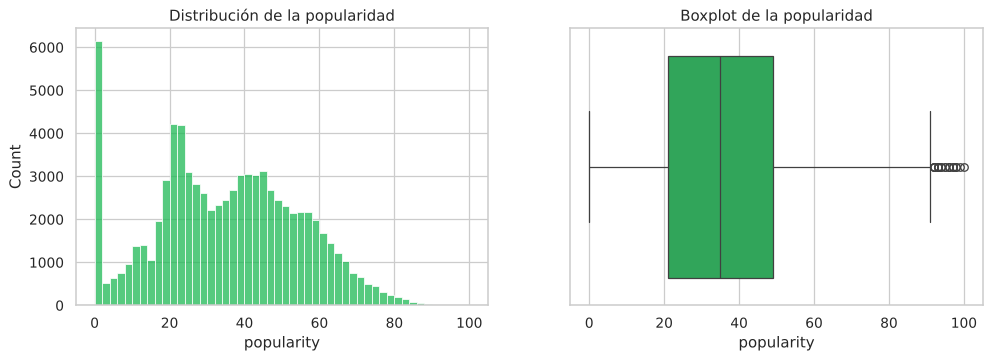

In [6]:
print(df["popularity"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["popularity"], bins=50, ax=axes[0], color="#1DB954")
axes[0].set_title("Distribución de la popularidad")
sns.boxplot(x=df["popularity"], ax=axes[1], color="#1DB954")
axes[1].set_title("Boxplot de la popularidad")
plt.savefig("../images/01_distribucion_popularidad.png", bbox_inches="tight")
plt.show()

- La popularidad promedio es **≈ 35** y la mitad de las canciones está entre 21 y 49.
- Hay un grupo de canciones con **popularidad 0** (≈ 7 %), que son canciones casi sin reproducciones recientes.
- Muy pocas canciones superan 80: los grandes éxitos son raros, lo que hace difícil predecirlos.

### 1.4 Variables numéricas vs popularidad

instrumentalness   -0.175
speechiness        -0.065
duration_ms        -0.053
acousticness       -0.032
liveness           -0.029
energy             -0.001
tempo               0.002
valence             0.011
danceability        0.087
loudness            0.090
Name: popularity, dtype: float64


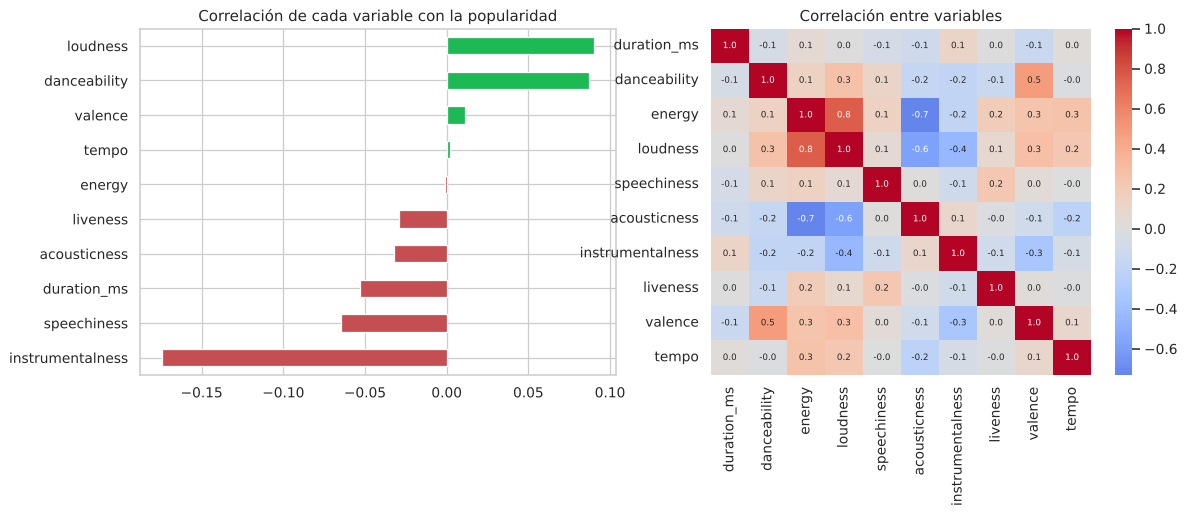

In [7]:
numericas = ["duration_ms", "danceability", "energy", "loudness", "speechiness", "acousticness",
             "instrumentalness", "liveness", "valence", "tempo"]

corr = df[numericas + ["popularity"]].corr()["popularity"].drop("popularity").sort_values()
print(corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
corr.plot(kind="barh", ax=axes[0], color=["#C44E52" if v < 0 else "#1DB954" for v in corr])
axes[0].set_title("Correlación de cada variable con la popularidad")
sns.heatmap(df[numericas].corr(), cmap="coolwarm", center=0, ax=axes[1], annot=True, fmt=".1f", annot_kws={"size": 7})
axes[1].set_title("Correlación entre variables")
plt.savefig("../images/02_correlaciones.png", bbox_inches="tight")
plt.show()

- Ninguna característica musical por sí sola explica mucho la popularidad (todas las correlaciones son menores a 0,2).
- La más fuerte es **`instrumentalness` (negativa)**: las canciones sin voz tienden a ser menos populares.
- `danceability` y `loudness` tienen una relación positiva leve.
- Entre variables, `energy` y `loudness` están muy correlacionadas (0,8), y `energy` con `acousticness` negativamente (−0,7).

Esto nos dice que la popularidad depende de **combinaciones** de variables, por eso conviene probar modelos que capten relaciones no lineales (árboles y ensambles).

### 1.5 Género y contenido explícito

Géneros distintos: 113


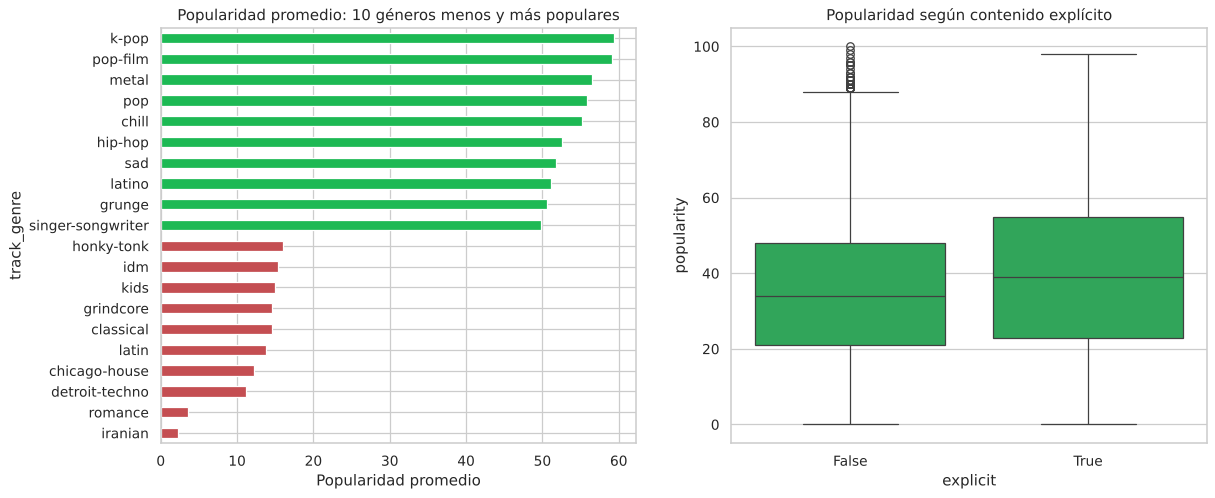

explicit
False    34.3
True     38.7
Name: popularity, dtype: float64


In [8]:
pop_genero = df.groupby("track_genre")["popularity"].mean().sort_values()
print("Géneros distintos:", df["track_genre"].nunique())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pd.concat([pop_genero.head(10), pop_genero.tail(10)]).plot(kind="barh", ax=axes[0],
    color=["#C44E52"] * 10 + ["#1DB954"] * 10)
axes[0].set_title("Popularidad promedio: 10 géneros menos y más populares")
axes[0].set_xlabel("Popularidad promedio")
sns.boxplot(data=df, x="explicit", y="popularity", ax=axes[1], color="#1DB954")
axes[1].set_title("Popularidad según contenido explícito")
plt.savefig("../images/03_genero_explicit.png", bbox_inches="tight")
plt.show()

print(df.groupby("explicit")["popularity"].mean().round(1))

- El **género** es lo que más diferencia la popularidad: hay géneros con promedio sobre 55 (k-pop, pop-film, metal) y otros bajo 10 (iranian, romance, detroit-techno). Hay **≈ 57 puntos** de diferencia entre géneros.
- Las canciones **explícitas** son algo más populares (≈ 39 vs 34).
- Conclusión: el género va a ser una variable clave para el modelo.

## 2. Preparación de los datos

Decisiones:
1. **Variables que no usamos:** `track_id`, `album_name`, `track_name` (son identificadores) y `artists`. El artista influye mucho en la popularidad, pero tiene más de 31.000 valores distintos y el modelo terminaría memorizando artistas famosos en vez de aprender de la música. Queremos un modelo que sirva también para **artistas nuevos**.
2. **Numéricas** (`duration_ms`, `loudness`, `tempo`, características 0–1, `mode`, `explicit`) → `StandardScaler`.
3. **`key` y `time_signature`** → One-Hot Encoding (son categorías, no cantidades).
4. **`track_genre`** tiene 114 categorías. Con One-Hot serían 114 columnas y los modelos de árboles se vuelven muy lentos. Usamos **Target Encoding**: cada género se reemplaza por la **popularidad promedio de ese género en train**. Para no hacer trampa, el `TargetEncoder` de scikit-learn calcula ese promedio con validación cruzada interna.
5. División **80 % train / 20 % test**. Todo va dentro de un **Pipeline**, así el preprocesamiento aprende solo de train (y dentro de cada fold).

In [9]:
col_num = ["duration_ms", "danceability", "energy", "loudness", "speechiness", "acousticness",
           "instrumentalness", "liveness", "valence", "tempo", "mode", "explicit"]
col_cat = ["key", "time_signature"]
col_genero = ["track_genre"]

X = df[col_num + col_cat + col_genero].copy()
X["explicit"] = X["explicit"].astype(int)
y = df["popularity"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

def crear_preprocesador():
    return ColumnTransformer([
        ("num", StandardScaler(), col_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), col_cat),
        ("gen", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), col_genero),
    ])

def crear_pipeline(modelo):
    return Pipeline([("prep", crear_preprocesador()), ("modelo", modelo)])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (65074, 15)  Test: (16269, 15)


## 3. Modelado

Probamos estos modelos de **regresión**:

| Modelo | Tipo | Por qué |
|---|---|---|
| Dummy (promedio) | Base | Siempre predice la popularidad promedio. Es la vara mínima. |
| **Ridge** | Lineal | Regresión lineal con regularización. Simple e interpretable. |
| Árbol de decisión | Árbol simple | Capta relaciones no lineales. Es el "ladrillo" de los ensambles. |
| **Random Forest** | Ensamble (bagging) | Muchos árboles entrenados con muestras distintas; se promedian. |
| **Gradient Boosting** (`HistGradientBoosting`) | Ensamble (boosting) | Árboles en secuencia, cada uno corrige los errores del anterior. |
| **Voting** | Ensamble de ensambles | Promedia las predicciones de Random Forest y Gradient Boosting. |

**Métricas:** RMSE (penaliza más los errores grandes), MAE (error promedio en puntos) y R² (% de la variación de la popularidad que explica el modelo).

### 3.1 Modelos con su configuración por defecto
Primero medimos cada modelo **sin optimizar**, con validación cruzada de 5 folds sobre train. Así después podemos ver cuánto mejora la optimización.

In [10]:
modelos_base = {
    "Dummy (promedio)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(),
    "Árbol de decisión": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

res_base = {}
for nombre, modelo in modelos_base.items():
    inicio = time.time()
    r2 = cross_val_score(crear_pipeline(modelo), X_train, y_train, cv=cv, scoring="r2", n_jobs=1)
    res_base[nombre] = r2.mean()
    print(f"{nombre:20s} R² CV = {r2.mean():.3f} ± {r2.std():.3f}   ({time.time() - inicio:.0f} s)")

Dummy (promedio)     R² CV = -0.000 ± 0.000   (2 s)
Ridge                R² CV = 0.379 ± 0.006   (1 s)
Árbol de decisión    R² CV = -0.201 ± 0.020   (5 s)
Random Forest        R² CV = 0.400 ± 0.004   (133 s)
Gradient Boosting    R² CV = 0.397 ± 0.005   (3 s)


- El **Dummy** tiene R² = 0: es la referencia mínima.
- **Ridge** ya explica el **38 %** de la variación (R² 0,379), sobre todo gracias al género.
- El **árbol de decisión sin límites** sale con R² **negativo** (−0,20): es peor que predecir el promedio. Crece hasta memorizar el train (sobreajuste extremo).
- **Random Forest** (0,400) y **Gradient Boosting** (0,397) son los mejores incluso sin optimizar.

### 3.2 Optimización de hiperparámetros

Para cada modelo buscamos la mejor combinación de hiperparámetros con **validación cruzada de 5 folds** sobre train (el test no se toca):
- **GridSearchCV** para Ridge y el árbol (pocos hiperparámetros, probamos todas las combinaciones).
- **RandomizedSearchCV** para Random Forest y Gradient Boosting (muchas combinaciones posibles, probamos una muestra al azar para ahorrar tiempo).

Métrica de selección: **RMSE** (en sklearn se usa `neg_root_mean_squared_error`, por eso los valores salen negativos).

In [11]:
busquedas = {}

# Ridge: fuerza de la regularización
busquedas["Ridge"] = GridSearchCV(
    crear_pipeline(Ridge()),
    {"modelo__alpha": [1, 10, 100, 1000, 3000, 10000]},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1)

# Árbol: limitar la profundidad y el tamaño de las hojas para que no memorice
busquedas["Árbol de decisión"] = GridSearchCV(
    crear_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    {"modelo__max_depth": [4, 6, 8, 10, 14], "modelo__min_samples_leaf": [20, 50, 100, 200]},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1)

for nombre in ["Ridge", "Árbol de decisión"]:
    inicio = time.time()
    busquedas[nombre].fit(X_train, y_train)
    print(f"{nombre}: RMSE CV = {-busquedas[nombre].best_score_:.2f}  mejores = {busquedas[nombre].best_params_}  ({time.time() - inicio:.0f} s)")

Ridge: RMSE CV = 15.31  mejores = {'modelo__alpha': 3000}  (2 s)
Árbol de decisión: RMSE CV = 15.29  mejores = {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 100}  (37 s)


In [12]:
# Random Forest (bagging)
busquedas["Random Forest"] = RandomizedSearchCV(
    crear_pipeline(RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
    {"modelo__max_depth": [15, 25, None],
     "modelo__min_samples_leaf": [3, 5, 10, 20],
     "modelo__max_features": [0.3, 0.5],
     "modelo__max_samples": [0.3, 0.5]},
    n_iter=6, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1, random_state=RANDOM_STATE)

# Gradient Boosting (boosting)
busquedas["Gradient Boosting"] = RandomizedSearchCV(
    crear_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    {"modelo__learning_rate": [0.03, 0.05, 0.1, 0.2],
     "modelo__max_iter": [200, 400, 800],
     "modelo__max_leaf_nodes": [15, 31, 63],
     "modelo__min_samples_leaf": [20, 50, 100],
     "modelo__l2_regularization": [0, 1, 10]},
    n_iter=15, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1, random_state=RANDOM_STATE)

for nombre in ["Random Forest", "Gradient Boosting"]:
    inicio = time.time()
    busquedas[nombre].fit(X_train, y_train)
    print(f"{nombre}: RMSE CV = {-busquedas[nombre].best_score_:.2f}  mejores = {busquedas[nombre].best_params_}  ({time.time() - inicio:.0f} s)")

Random Forest: RMSE CV = 14.99  mejores = {'modelo__min_samples_leaf': 3, 'modelo__max_samples': 0.3, 'modelo__max_features': 0.5, 'modelo__max_depth': None}  (119 s)
Gradient Boosting: RMSE CV = 15.04  mejores = {'modelo__min_samples_leaf': 50, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 1}  (106 s)


### 3.3 Técnicas de ensamble

Ahora comparamos todos los modelos optimizados usando **predicciones de validación cruzada** (cada canción de train se predice con un modelo que no la vio). Así podemos medir también el **Voting**: promediar las predicciones de Random Forest y Gradient Boosting.

In [13]:
modelos_opt = {"Dummy (promedio)": crear_pipeline(DummyRegressor(strategy="mean"))}
modelos_opt.update({nombre: b.best_estimator_ for nombre, b in busquedas.items()})

pred_cv = {}
for nombre, modelo in modelos_opt.items():
    inicio = time.time()
    pred_cv[nombre] = cross_val_predict(modelo, X_train, y_train, cv=cv, n_jobs=1)
    print(f"{nombre:20s} listo ({time.time() - inicio:.0f} s)")

# Voting: promedio simple de Random Forest y Gradient Boosting
pred_cv["Voting (RF + GB)"] = (pred_cv["Random Forest"] + pred_cv["Gradient Boosting"]) / 2

# Stacking: un modelo lineal aprende cuánto confiar en cada modelo (usa las predicciones de validación cruzada)
base_stack = ["Ridge", "Random Forest", "Gradient Boosting"]
meta = LinearRegression(positive=True)
oof = np.column_stack([pred_cv[n] for n in base_stack])
pred_cv["Stacking (Ridge + RF + GB)"] = cross_val_predict(meta, oof, y_train, cv=cv)
meta.fit(oof, y_train)
print("Pesos del stacking:", dict(zip(base_stack, meta.coef_.round(2))), " intercepto:", round(meta.intercept_, 2))

# R² de cada fold, para ver qué tan estable es cada modelo (desviación estándar)
folds = [val for _, val in cv.split(X_train)]
def r2_por_fold(p):
    return [r2_score(y_train.iloc[f], p[f]) for f in folds]

tabla_cv = pd.DataFrame({nombre: {"RMSE": rmse(y_train, p), "MAE": mean_absolute_error(y_train, p),
                                  "R²": np.mean(r2_por_fold(p)), "R² std": np.std(r2_por_fold(p))}
                         for nombre, p in pred_cv.items()}).T.round(3)
tabla_cv

Dummy (promedio)     listo (0 s)
Ridge                listo (0 s)
Árbol de decisión    listo (2 s)
Random Forest        listo (22 s)
Gradient Boosting    listo (10 s)
Pesos del stacking: {'Ridge': np.float64(0.0), 'Random Forest': np.float64(0.66), 'Gradient Boosting': np.float64(0.36)}  intercepto: -0.76


,RMSE,MAE,R²,R² std
Dummy (promedio),19.431,16.159,-0.000,0.000
Ridge,15.312,10.785,0.379,0.006
Árbol de decisión,15.289,10.697,0.381,0.006
Random Forest,14.992,10.417,0.405,0.005
Gradient Boosting,15.038,10.508,0.401,0.004
Voting (RF + GB),14.977,10.428,0.406,0.005
Stacking (Ridge + RF + GB),14.973,10.364,0.406,0.005


                   R² CV por defecto  R² CV optimizado  Brecha train−CV por defecto  Brecha train−CV optimizado  Mejora R² CV
Ridge                          0.379             0.379                        0.004                       0.004         0.000
Árbol de decisión             -0.201             0.381                        0.901                       0.021         0.582
Random Forest                  0.400             0.405                        0.430                       0.173         0.005
Gradient Boosting              0.397             0.401                        0.037                       0.062         0.004


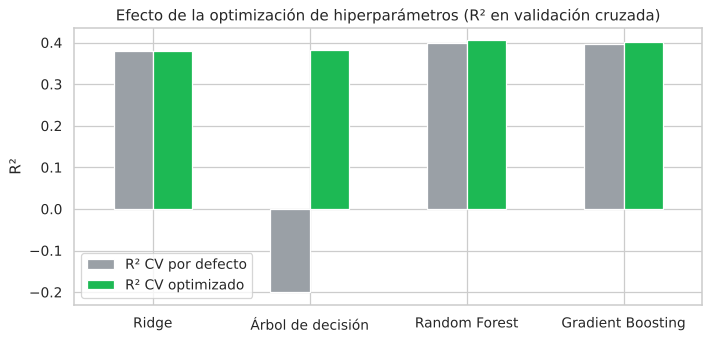

In [14]:
# ¿Cuánto mejoró la optimización de hiperparámetros?
# También medimos el R² en train para ver la brecha train - CV (sobreajuste)
r2_train_base, r2_train_opt = {}, {}
for nombre in busquedas:
    r2_train_base[nombre] = r2_score(y_train, crear_pipeline(modelos_base[nombre]).fit(X_train, y_train).predict(X_train))
    r2_train_opt[nombre] = r2_score(y_train, busquedas[nombre].best_estimator_.fit(X_train, y_train).predict(X_train))

optimizacion = pd.DataFrame({"R² CV por defecto": pd.Series(res_base),
                             "R² CV optimizado": tabla_cv["R²"],
                             "Brecha train−CV por defecto": pd.Series(r2_train_base) - pd.Series(res_base),
                             "Brecha train−CV optimizado": pd.Series(r2_train_opt) - tabla_cv["R²"]}).loc[list(busquedas)]
optimizacion["Mejora R² CV"] = optimizacion["R² CV optimizado"] - optimizacion["R² CV por defecto"]
print(optimizacion.round(3).to_string())

optimizacion[["R² CV por defecto", "R² CV optimizado"]].plot(kind="bar", rot=0, figsize=(9, 4), color=["#9AA0A6", "#1DB954"])
plt.title("Efecto de la optimización de hiperparámetros (R² en validación cruzada)")
plt.ylabel("R²")
plt.savefig("../images/04_optimizacion.png", bbox_inches="tight")
plt.show()

**Resultados de la optimización:**
- **Árbol de decisión:** la mejora es enorme, de R² −0,20 a **0,38**. Limitar la profundidad (`max_depth = 8`) y exigir hojas grandes (`min_samples_leaf = 100`) eliminó el sobreajuste: la brecha train−CV bajó de 0,90 a 0,02.
- **Random Forest:** el R² sube de 0,400 a **0,405** y la brecha train−CV baja de **0,43 a 0,17**. Usar solo el 30 % de las canciones por árbol (`max_samples = 0,3`) y la mitad de las variables (`max_features = 0,5`) lo hace generalizar mejor.
- **Gradient Boosting:** sube de 0,397 a 0,401 con una tasa de aprendizaje más baja (0,03) y más iteraciones (400), aunque su brecha train−CV crece un poco (0,04 → 0,06).
- **Ridge:** no cambia; el modelo lineal ya estaba en su límite (`alpha = 3000`).

Conclusión: la optimización ayuda sobre todo a **controlar el sobreajuste**. El R² sube poco porque el límite lo ponen los datos: sin información del artista ni de la promoción, la música explica solo una parte de la popularidad.

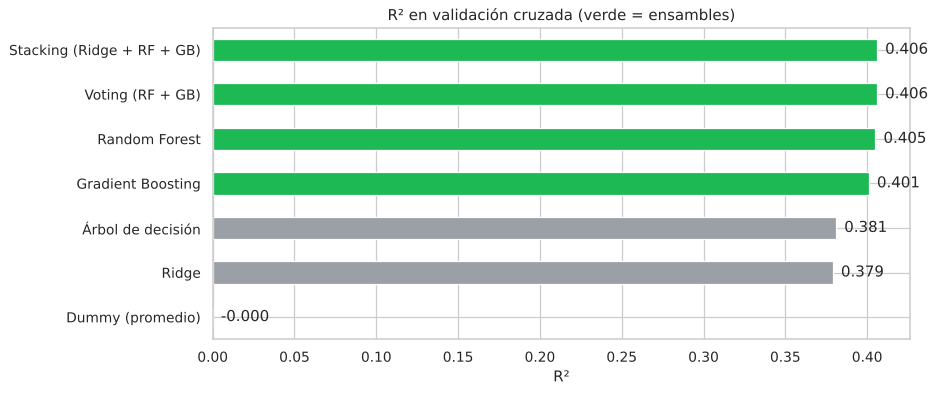

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
orden = tabla_cv.sort_values("R²")
colores = ["#9AA0A6" if n in ["Dummy (promedio)", "Ridge", "Árbol de decisión"] else "#1DB954" for n in orden.index]
orden["R²"].plot(kind="barh", ax=ax, color=colores)
for i, v in enumerate(orden["R²"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_title("R² en validación cruzada (verde = ensambles)")
ax.set_xlabel("R²")
plt.savefig("../images/05_comparacion_modelos_cv.png", bbox_inches="tight")
plt.show()

**¿Aportan los ensambles?**
- **Bagging (Random Forest)** vs un solo árbol optimizado: R² 0,381 → **0,405** y RMSE 15,29 → 14,99 (≈ 2 % menos error).
- **Boosting (Gradient Boosting):** R² 0,401, también sobre el árbol y sobre Ridge.
- **Voting** (promedio de RF y GB) y **Stacking:** R² **0,406**, solo 0,001 sobre el Random Forest solo. El stacking le dio peso 0 a Ridge y repartió entre RF (0,66) y GB (0,36).

Los ensambles mejoran frente a los modelos simples, pero **combinar ensambles (Voting y Stacking) casi no agrega nada** sobre el Random Forest: la diferencia (0,001) es mucho menor que la variación entre folds (± 0,005).

### 3.4 Selección del modelo final (antes de mirar el test)

Aplicamos la regla que definimos al inicio, **solo con los resultados de validación cruzada**:
1. Gana el modelo con **mayor R² en validación cruzada**.
2. Si otros modelos quedan **a menos de 0,005** del mejor, elegimos el **más simple** de ellos. Orden de complejidad: Ridge < Árbol < Random Forest = Gradient Boosting < Voting < Stacking.

Así no premiamos a un modelo más complejo por una diferencia que puede ser solo ruido (la desviación estándar entre folds es de ≈ 0,005).

In [16]:
complejidad = {"Dummy (promedio)": 0, "Ridge": 1, "Árbol de decisión": 2, "Random Forest": 3,
               "Gradient Boosting": 3, "Voting (RF + GB)": 4, "Stacking (Ridge + RF + GB)": 5}
ranking = tabla_cv[["R²", "R² std"]].copy()
ranking["Complejidad"] = ranking.index.map(complejidad)
ranking = ranking.sort_values("R²", ascending=False)
mejor_r2 = ranking["R²"].max()
empatados = ranking[ranking["R²"] >= mejor_r2 - 0.005].sort_values(["Complejidad", "R²"], ascending=[True, False])
MODELO_FINAL = empatados.index[0]

print(ranking.to_string())
print("\nModelos a menos de 0,005 del mejor:", list(empatados.index))
print("Modelo final elegido por la regla:", MODELO_FINAL)

                               R²  R² std  Complejidad
Stacking (Ridge + RF + GB)  0.406   0.005            5
Voting (RF + GB)            0.406   0.005            4
Random Forest               0.405   0.005            3
Gradient Boosting           0.401   0.004            3
Árbol de decisión           0.381   0.006            2
Ridge                       0.379   0.006            1
Dummy (promedio)           -0.000   0.000            0

Modelos a menos de 0,005 del mejor: ['Random Forest', 'Gradient Boosting', 'Voting (RF + GB)', 'Stacking (Ridge + RF + GB)']
Modelo final elegido por la regla: Random Forest


**Aplicación de la regla:**
- El mejor R² en validación cruzada es **0,406** (Voting y Stacking).
- A menos de 0,005 quedan también el **Random Forest (0,405)** y el **Gradient Boosting (0,401)**.
- De esos, los más simples son RF y GB; entre ellos gana el de mayor R²: **Random Forest**.

**Modelo final: Random Forest optimizado.** Rinde prácticamente igual que el Voting y el Stacking, pero es un solo modelo: más simple de entrenar, explicar y mantener. Esta decisión se tomó **sin mirar el test**.

## 4. Evaluación en test y capacidad de generalización

Entrenamos los modelos optimizados con todo el train y los evaluamos **una sola vez** en el test (20 % que el modelo nunca vio).

In [17]:
pred_test, pred_train = {}, {}
for nombre, modelo in modelos_opt.items():
    modelo.fit(X_train, y_train)
    pred_test[nombre] = modelo.predict(X_test)
    pred_train[nombre] = modelo.predict(X_train)
pred_test["Voting (RF + GB)"] = (pred_test["Random Forest"] + pred_test["Gradient Boosting"]) / 2
pred_train["Voting (RF + GB)"] = (pred_train["Random Forest"] + pred_train["Gradient Boosting"]) / 2
pred_test["Stacking (Ridge + RF + GB)"] = meta.predict(np.column_stack([pred_test[n] for n in base_stack]))
pred_train["Stacking (Ridge + RF + GB)"] = meta.predict(np.column_stack([pred_train[n] for n in base_stack]))

filas = []
for nombre in pred_test:
    filas.append([nombre, r2_score(y_train, pred_train[nombre]), tabla_cv.loc[nombre, "R²"], r2_score(y_test, pred_test[nombre]),
                  rmse(y_test, pred_test[nombre]), mean_absolute_error(y_test, pred_test[nombre])])
resultados = pd.DataFrame(filas, columns=["Modelo", "R² train", "R² CV", "R² test", "RMSE test", "MAE test"]).set_index("Modelo")
resultados.insert(2, "R² CV std", tabla_cv.loc[resultados.index, "R² std"])
resultados["Diferencia CV − test"] = resultados["R² CV"] - resultados["R² test"]
resultados = resultados.round(3)
resultados.to_csv("../models/resultados_modelos.csv")
resultados

,R² train,R² CV,R² CV std,R² test,RMSE test,MAE test,Diferencia CV − test
Modelo,,,,,,,
Dummy (promedio),0.000,-0.000,0.000,-0.000,19.471,16.217,0.000
Ridge,0.383,0.379,0.006,0.390,15.205,10.703,-0.011
Árbol de decisión,0.402,0.381,0.006,0.391,15.195,10.618,-0.010
Random Forest,0.578,0.405,0.005,0.415,14.888,10.364,-0.010
Gradient Boosting,0.463,0.401,0.004,0.411,14.943,10.429,-0.010
Voting (RF + GB),0.526,0.406,0.005,0.416,14.877,10.361,-0.010
Stacking (Ridge + RF + GB),0.545,0.406,0.005,0.417,14.868,10.297,-0.011


**Capacidad de generalización:**
- En todos los modelos el R² de validación cruzada y el de test son casi iguales (diferencia ≈ 0,01), así que **funcionan igual con canciones nuevas**. Cumple el KPI (≤ 0,02).
- La **desviación estándar entre folds es baja** (≈ 0,005): el resultado no depende de cómo se dividieron los datos.
- El test sale incluso un poco mejor que la validación cruzada (0,415 vs 0,405 en el RF), lo que descarta que hayamos "ajustado" el modelo al test.
- El **Random Forest** tiene una brecha train−test de 0,16 (0,578 vs 0,415): se ajusta algo a train, pero eso no lo hace fallar en datos nuevos.

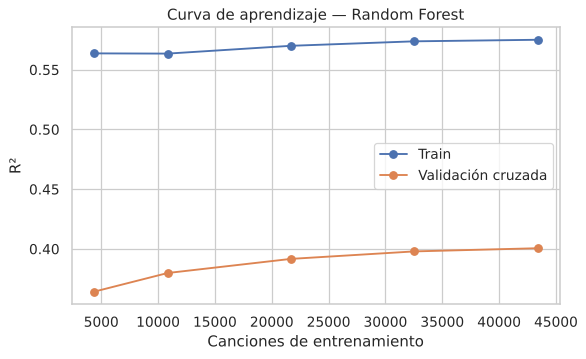

R² train: [0.564 0.563 0.57  0.574 0.575]
R² CV:    [0.364 0.38  0.392 0.398 0.401]


In [18]:
# Curva de aprendizaje del modelo final: ¿mejora con más datos? ¿hay sobreajuste?
# (usamos 3 folds para que no tarde demasiado)
from sklearn.ensemble import VotingRegressor
if MODELO_FINAL == "Voting (RF + GB)":
    modelo_lc = VotingRegressor([("rf", busquedas["Random Forest"].best_estimator_), ("gb", busquedas["Gradient Boosting"].best_estimator_)])
elif MODELO_FINAL in busquedas:
    modelo_lc = busquedas[MODELO_FINAL].best_estimator_
else:
    modelo_lc = busquedas["Gradient Boosting"].best_estimator_
tamanos, sc_train, sc_val = learning_curve(modelo_lc, X_train, y_train, cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
                                           train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], scoring="r2", n_jobs=1)
plt.figure(figsize=(7, 4))
plt.plot(tamanos, sc_train.mean(axis=1), "o-", label="Train")
plt.plot(tamanos, sc_val.mean(axis=1), "o-", label="Validación cruzada")
plt.xlabel("Canciones de entrenamiento"); plt.ylabel("R²"); plt.title(f"Curva de aprendizaje — {MODELO_FINAL}")
plt.legend()
plt.savefig("../images/06_curva_aprendizaje.png", bbox_inches="tight")
plt.show()
print("R² train:", sc_train.mean(axis=1).round(3))
print("R² CV:   ", sc_val.mean(axis=1).round(3))

- El R² de validación sube de **0,36** (10 % de los datos) a **0,40** (todos los datos), mientras el de train se mantiene cerca de 0,57.
- Al final la curva de validación sube muy poco (0,398 → 0,401 en el último tramo): **más canciones del mismo tipo ayudarían, pero poco**.
- La brecha entre train y validación (≈ 0,17) es la varianza propia del Random Forest. Para mejorar de verdad harían falta **otras variables** (artista, promoción, redes sociales).

In [19]:
# ¿Funciona con artistas que el modelo nunca vio?
artistas_train = set(df.loc[X_train.index, "artists"])
artista_conocido = df.loc[X_test.index, "artists"].isin(artistas_train).values
p = pred_test[MODELO_FINAL]
for etiqueta, m in [("Artista que aparece en train", artista_conocido), ("Artista nuevo (no está en train)", ~artista_conocido)]:
    print(f"{etiqueta:35s} n={m.sum():6d}  R²={r2_score(y_test[m], p[m]):.3f}  MAE={mean_absolute_error(y_test[m], p[m]):.2f}")

Artista que aparece en train        n= 11629  R²=0.436  MAE=10.00
Artista nuevo (no está en train)    n=  4640  R²=0.350  MAE=11.27


El modelo funciona mejor con canciones de artistas que ya aparecen en train (R² 0,44) que con artistas nuevos (R² 0,35, MAE 11,3). Aunque no usamos el nombre del artista, sus canciones se parecen entre sí, así que el modelo "reconoce" su estilo. Para artistas nuevos sigue siendo útil, pero hay que esperar un error algo mayor.

## 5. Resultado del modelo final

Modelo final: Random Forest
R² test = 0.415 | RMSE = 14.89 | MAE = 10.36
Mejora del RMSE frente al modelo base: 23.5%


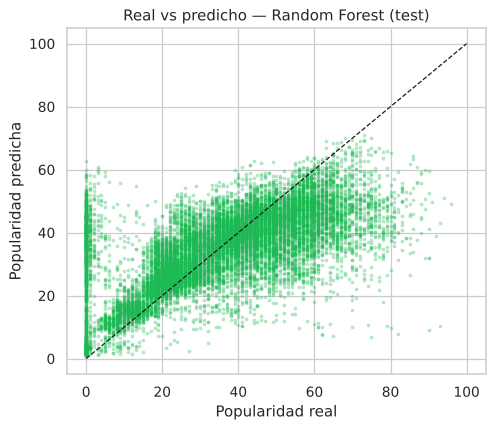

In [20]:
base = resultados.loc["Dummy (promedio)", "RMSE test"]
final = resultados.loc[MODELO_FINAL]
print(f"Modelo final: {MODELO_FINAL}")
print(f"R² test = {final['R² test']:.3f} | RMSE = {final['RMSE test']:.2f} | MAE = {final['MAE test']:.2f}")
print(f"Mejora del RMSE frente al modelo base: {(1 - final['RMSE test'] / base):.1%}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, pred_test[MODELO_FINAL], s=4, alpha=0.25, color="#1DB954")
ax.plot([0, 100], [0, 100], "k--", lw=1)
ax.set_xlabel("Popularidad real"); ax.set_ylabel("Popularidad predicha")
ax.set_title(f"Real vs predicho — {MODELO_FINAL} (test)")
plt.savefig("../images/07_real_vs_predicho.png", bbox_inches="tight")
plt.show()

**Modelo final: Random Forest optimizado** (elegido por la regla de la sección 3.4, antes de ver el test).

| Modelo | R² CV (± std) | R² test | MAE test | Brecha train−test |
|---|---|---|---|---|
| Ridge | 0,379 ± 0,006 | 0,390 | 10,70 | −0,007 |
| Árbol (optimizado) | 0,381 ± 0,006 | 0,391 | 10,62 | 0,011 |
| **Random Forest** | **0,405 ± 0,005** | **0,415** | **10,36** | 0,163 |
| Gradient Boosting | 0,401 ± 0,004 | 0,411 | 10,43 | 0,052 |
| Voting (RF + GB) | 0,406 ± 0,005 | 0,416 | 10,36 | 0,110 |
| Stacking | 0,406 ± 0,005 | 0,417 | 10,30 | 0,128 |

El test confirma la decisión: Voting y Stacking quedan apenas 0,001–0,002 sobre el Random Forest, una diferencia sin importancia práctica.

**Cumplimiento de KPIs:** R² 0,415 (meta ≥ 0,40 ✓), MAE 10,4 puntos (meta ≤ 11 ✓), RMSE 23,5 % mejor que el modelo base (meta ≥ 20 % ✓), diferencia CV−test 0,010 (meta ≤ 0,02 ✓).

En el gráfico se ve que el modelo **acierta la tendencia pero "aplana" los extremos**: le cuesta predecir canciones con popularidad 0 o sobre 80, porque esos casos dependen de cosas que no están en los datos.

### 5.1 ¿Qué variables usa más el modelo?

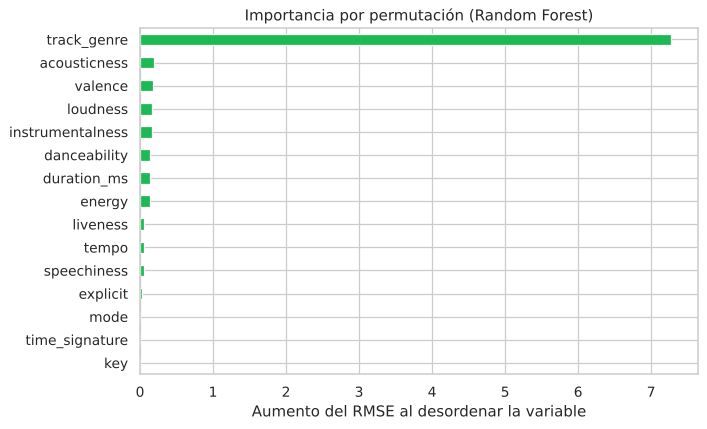

track_genre         7.28
acousticness        0.20
valence             0.17
loudness            0.17
instrumentalness    0.17
danceability        0.14
duration_ms         0.14
energy              0.14
liveness            0.06
tempo               0.05
speechiness         0.05
explicit            0.02
mode                0.00
time_signature      0.00
key                 0.00

In [21]:
# Importancia por permutación: cuánto empeora el RMSE si desordenamos cada variable (en una muestra del test)
muestra = X_test.sample(4000, random_state=RANDOM_STATE)
modelo_imp = busquedas[MODELO_FINAL].best_estimator_ if MODELO_FINAL in busquedas else busquedas["Gradient Boosting"].best_estimator_
imp = permutation_importance(modelo_imp, muestra, y_test.loc[muestra.index],
                             scoring="neg_root_mean_squared_error", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importancia = pd.Series(imp.importances_mean, index=muestra.columns).sort_values()

importancia.plot(kind="barh", figsize=(8, 5), color="#1DB954")
plt.title(f"Importancia por permutación ({MODELO_FINAL if MODELO_FINAL in busquedas else 'Gradient Boosting'})")
plt.xlabel("Aumento del RMSE al desordenar la variable")
plt.savefig("../images/08_importancia_variables.png", bbox_inches="tight")
plt.show()
importancia.sort_values(ascending=False).round(2)

- El **género** es por lejos lo más importante: si lo desordenamos, el error sube ≈ 7,3 puntos.
- Después vienen `acousticness`, `valence`, `loudness` e `instrumentalness`, con efectos mucho menores (≈ 0,2 puntos).
- `key`, `mode` y `time_signature` casi no aportan.

Para el negocio: **el género en el que se publica una canción pesa mucho más que sus detalles de sonido**. Ojo: esto es asociación, no causa; el género pesa porque ya trae una popularidad histórica.

### 5.2 ¿Sirve para el negocio?
Un sello no necesita adivinar la popularidad exacta: necesita **ordenar** las canciones y elegir a cuáles apostar. Revisamos qué pasa si promociona el **10 % de canciones con mayor popularidad predicha**. Definimos "hit" como popularidad ≥ 50 (≈ el 25 % más popular).

In [22]:
hit = (y_test >= 50).values
orden = np.argsort(-pred_test[MODELO_FINAL])
filas = []
for pct in [0.05, 0.10, 0.20]:
    top = orden[:int(len(orden) * pct)]
    filas.append([f"Top {pct:.0%}", len(top), hit[top].mean(), hit[top].mean() / hit.mean()])
negocio = pd.DataFrame(filas, columns=["Grupo", "Canciones", "% de hits", "Lift vs azar"]).set_index("Grupo")
print(f"% de hits en todo el test (elegir al azar): {hit.mean():.1%}")
negocio.round(3)

% de hits en todo el test (elegir al azar): 24.2%


,Canciones,% de hits,Lift vs azar
Grupo,,,
Top 5%,813,0.807,3.339
Top 10%,1626,0.724,2.998
Top 20%,3253,0.605,2.504


- Elegir al azar da un **24,2 %** de hits.
- Si el sello promociona el **10 %** de canciones con mayor predicción, el **72 %** son hits: **3 veces mejor que al azar** (KPI ≥ 60 % ✓).
- En el 5 % superior llega al 81 %.

Aunque el R² es moderado, el modelo **ordena muy bien** las canciones, y eso es lo que el negocio necesita para priorizar.

## 6. Aprendizaje no supervisado: perfiles musicales con K-Means

Agrupamos las canciones solo por sus **características de sonido** (sin usar popularidad ni género) para encontrar perfiles musicales. Después vemos qué popularidad y qué géneros tiene cada grupo.

k = 2  inercia = 573683  silueta = 0.255
k = 3  inercia = 508595  silueta = 0.163
k = 4  inercia = 456932  silueta = 0.169
k = 5  inercia = 411722  silueta = 0.176
k = 6  inercia = 373827  silueta = 0.188
k = 7  inercia = 340265  silueta = 0.194
k = 8  inercia = 321888  silueta = 0.176


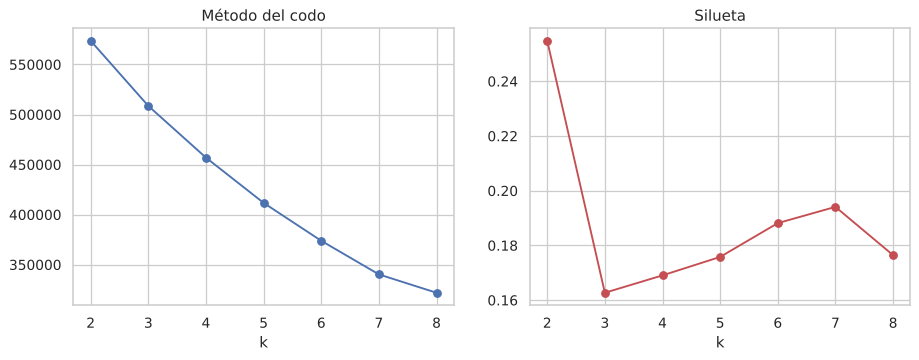

In [23]:
vars_musica = ["danceability", "energy", "loudness", "speechiness", "acousticness",
               "instrumentalness", "liveness", "valence", "tempo"]
escalador_km = StandardScaler()
Z = escalador_km.fit_transform(df[vars_musica])

inercias, siluetas = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z, km.labels_, sample_size=5000, random_state=RANDOM_STATE))
    print("k =", k, " inercia =", round(km.inertia_), " silueta =", round(siluetas[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2, 9), inercias, "o-"); axes[0].set_title("Método del codo"); axes[0].set_xlabel("k")
axes[1].plot(range(2, 9), siluetas, "o-", color="#C44E52"); axes[1].set_title("Silueta"); axes[1].set_xlabel("k")
plt.savefig("../images/09_eleccion_k.png", bbox_inches="tight")
plt.show()

La silueta es baja para todos los k (0,16–0,26): las canciones no forman grupos muy separados, porque las características musicales cambian de forma continua. k = 2 tiene la mayor silueta, pero solo separa "acústico" de "electrónico" y no sirve para tomar decisiones. Elegimos **k = 5**: la inercia sigue bajando a buen ritmo hasta ahí y los grupos se pueden interpretar.

In [24]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)
df["cluster"] = kmeans.labels_

perfil = df.groupby("cluster")[vars_musica + ["popularity"]].mean()
perfil["canciones"] = df["cluster"].value_counts()
perfil["% hits"] = df.groupby("cluster")["popularity"].apply(lambda s: (s >= 50).mean())
perfil["géneros más comunes"] = df.groupby("cluster")["track_genre"].agg(lambda s: ", ".join(s.value_counts().index[:3]))
perfil.round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularity,canciones,% hits,géneros más comunes
cluster,,,,,,,,,,,,,
0,0.69,0.73,-6.61,0.09,0.21,0.07,0.20,0.69,121.24,36.05,29836,0.25,"forro, salsa, kids"
1,0.35,0.19,-20.87,0.05,0.83,0.78,0.17,0.17,102.97,29.07,6860,0.20,"sleep, new-age, ambient"
2,0.47,0.82,-6.03,0.08,0.07,0.25,0.26,0.32,135.70,33.85,24764,0.22,"grindcore, black-metal, heavy-metal"
3,0.54,0.39,-10.50,0.06,0.66,0.07,0.19,0.40,113.93,36.03,18809,0.27,"tango, cantopop, romance"
4,0.57,0.68,-11.10,0.83,0.74,0.01,0.67,0.45,101.04,24.86,1074,0.04,"comedy, show-tunes, kids"


{np.int32(4): 'Hablado (comedia/infantil)', np.int32(1): 'Instrumental y ambiental', np.int32(2): 'Intenso y energético', np.int32(3): 'Acústico y suave', 0: 'Bailable y alegre'}


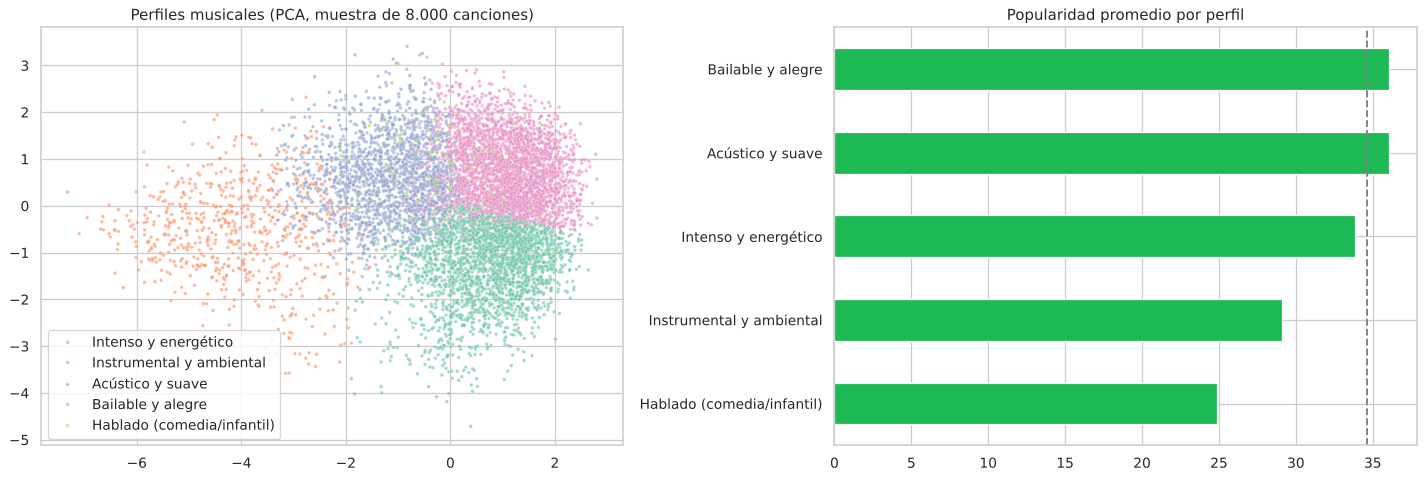

In [25]:
# Nombramos cada grupo según su rasgo más marcado (centroides)
c = perfil[vars_musica]
NOMBRES, libres = {}, list(c.index)
for nombre, var, mayor in [("Hablado (comedia/infantil)", "speechiness", True), ("Instrumental y ambiental", "instrumentalness", True),
                           ("Intenso y energético", "energy", True), ("Acústico y suave", "acousticness", True)]:
    grupo = c.loc[libres, var].idxmax()
    NOMBRES[grupo] = nombre
    libres.remove(grupo)
for grupo in libres:
    NOMBRES[grupo] = "Bailable y alegre"
print(NOMBRES)
df["perfil"] = df["cluster"].map(NOMBRES)

P = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z)
muestra_idx = np.random.RandomState(RANDOM_STATE).choice(len(df), 8000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(x=P[muestra_idx, 0], y=P[muestra_idx, 1], hue=df["perfil"].values[muestra_idx], s=8, alpha=0.6, palette="Set2", ax=axes[0])
axes[0].set_title("Perfiles musicales (PCA, muestra de 8.000 canciones)")
pop = df.groupby("perfil")["popularity"].mean().sort_values()
pop.plot(kind="barh", ax=axes[1], color="#1DB954")
axes[1].axvline(df["popularity"].mean(), ls="--", color="gray")
axes[1].set_title("Popularidad promedio por perfil"); axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("../images/10_perfiles_kmeans.png", bbox_inches="tight")
plt.show()

| Perfil | Canciones | Cómo suena | Popularidad | % hits |
|---|---|---|---|---|
| **Bailable y alegre** | 29.836 | Mucha danceability y valence (forró, salsa) | **36,1** | 25 % |
| **Acústico y suave** | 18.809 | Acústico, poca energía (tango, cantopop) | 36,0 | 27 % |
| **Intenso y energético** | 24.764 | Mucha energía, fuerte, rápido (metal) | 33,9 | 22 % |
| **Instrumental y ambiental** | 6.860 | Sin voz, muy suave (sleep, ambient, new-age) | 29,1 | 20 % |
| **Hablado (comedia/infantil)** | 1.074 | Mucho texto hablado (comedy, show-tunes) | **24,9** | 4 % |

- Los perfiles **bailables** y **acústicos con voz** son los más populares; los **instrumentales** y **hablados**, los menos. Coincide con el EDA: `instrumentalness` era la variable con correlación más negativa.
- Las diferencias de popularidad entre perfiles (≈ 11 puntos) son menores que entre géneros (≈ 57 puntos): **el sonido solo no define el éxito**.
- Uso para el negocio: armar playlists por perfil y recomendar a artistas de perfiles poco populares que destaquen la voz o el ritmo.

## 7. Sesgos, limitaciones y consideraciones éticas

**Sesgos:**
- **Sesgo de género musical y regional:** el modelo aprende que géneros como *iranian* o *romance* tienen baja popularidad. Si se usa para decidir qué promocionar, podría **reforzar** que la música de nicho o de ciertas regiones reciba menos apoyo, aunque la causa sea la falta de promoción y no la calidad.
- **Círculo vicioso de la popularidad:** la popularidad de Spotify depende de las reproducciones, que a su vez dependen de las playlists y recomendaciones. Un modelo entrenado con esto puede repetir lo que ya es popular ("el rico se hace más rico").
- **Artistas nuevos:** el modelo funciona peor con ellos (R² 0,35 vs 0,44), así que puede subestimar a talentos emergentes.

**Limitaciones:**
- Faltan variables clave: fama del artista, presupuesto de promoción, fecha de lanzamiento y redes sociales. Por eso el R² se queda en ≈ 0,42.
- La popularidad es una **foto de un momento**: cambia con el tiempo.
- Al dejar una fila por canción, cada canción queda con un solo género (el primero del archivo), aunque en Spotify pueda pertenecer a varios.
- El modelo predice bien el orden, pero se equivoca más en los extremos (popularidad 0 o > 80).

**Uso responsable:**
- Usarlo como **apoyo** para priorizar, no para descartar canciones o artistas automáticamente.
- Revisar los resultados por género antes de cada campaña y reservar parte del presupuesto para géneros de nicho.
- Los datos son públicos y no contienen información personal de usuarios.

## 8. Guardar el modelo

In [26]:
if MODELO_FINAL in busquedas:
    joblib.dump(busquedas[MODELO_FINAL].best_estimator_, "../models/modelo_final.joblib", compress=3)
else:
    joblib.dump({"rf": busquedas["Random Forest"].best_estimator_, "gb": busquedas["Gradient Boosting"].best_estimator_},
                "../models/modelo_final.joblib", compress=3)
joblib.dump({"scaler": escalador_km, "kmeans": kmeans, "variables": vars_musica, "nombres": NOMBRES}, "../models/kmeans_perfiles.joblib")
config = {"modelo_final": MODELO_FINAL, "archivo": "modelo_final.joblib",
          "regla_seleccion": "mayor R² en CV; si hay modelos a menos de 0,005 del mejor, el más simple",
          "variables": list(X.columns), "metricas_test": resultados.loc[MODELO_FINAL].to_dict(),
          "mejores_hiperparametros": {n: {k.replace("modelo__", ""): (v if not isinstance(v, np.generic) else v.item())
                                         for k, v in b.best_params_.items()} for n, b in busquedas.items()}}
with open("../models/config_modelo.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2, default=str)
print("Modelos guardados en models/")

Modelos guardados en models/


## 9. Conclusiones

**Hallazgos principales:**
1. **El género es el factor más importante**: hay ≈ 57 puntos de diferencia de popularidad entre géneros. Las características de sonido aportan poco por sí solas; la más relevante es `instrumentalness` (las canciones sin voz son menos populares).
2. La **optimización de hiperparámetros** sirvió sobre todo para **controlar el sobreajuste** (el árbol pasó de R² −0,20 a 0,38; el Random Forest redujo su brecha train−CV de 0,43 a 0,17).
3. Los **ensambles** superan a los modelos simples (≈ 2 % menos error), pero combinar ensambles (Voting, Stacking) no agrega una mejora significativa sobre el Random Forest.
4. Con una **regla definida antes de ver el test**, elegimos el **Random Forest optimizado**: R² 0,415 y MAE 10,4 puntos en test, generaliza bien (CV y test casi iguales, desviación entre folds ± 0,005) y cumple todos los KPIs.
5. Para el negocio, lo más útil es que **ordena bien**: del 10 % de canciones con mayor predicción, el 72 % son hits (3 veces mejor que al azar).
6. Con **K-Means** encontramos 5 perfiles musicales; los **bailables** y **acústicos con voz** son los más populares, y los **instrumentales** y **hablados**, los menos.

**Recomendaciones:**
- Usar el modelo para **priorizar** qué canciones promocionar o proponer a playlists, empezando por el 10–20 % con mayor predicción.
- Considerar el **género** de lanzamiento como una decisión estratégica clave.
- Usar los **perfiles de K-Means** para armar playlists y para orientar a artistas.
- Para mejorar el modelo, **agregar datos** de artista, promoción y fecha de lanzamiento: la curva de aprendizaje muestra que más canciones del mismo tipo ayudan muy poco.
- Revisar periódicamente los posibles **sesgos contra géneros de nicho y artistas nuevos**.